# P4 Theory · Transformer와 LLM의 기본 이해

**수업 목표:** 원래 Transformer의 **Encoder–Decoder 아키텍처**를 이해한 후, 사전훈련된 모델을 이용한 **영어→스페인어 번역**과 **Decoder-only 언어 생성**을 연결한다. 마지막으로 두 구조를 결합하는 문서 검색·답변 생성 프로젝트의 기본 아이디어를 이해한다.

**범위:** Transformer와 LLM의 기본 원리를 설명하는 내용. 수학적 유도, 역전파, 직접 모델 훈련, 강화학습은 다루지 않는다.

> 핵심 질문: **입력된 문장은 어떻게 숫자가 되고, Transformer는 이를 어떻게 처리하며, 모델은 어떻게 문장을 출력할까?**

**배경 자료:** Vaswani et al. (2017), *Attention Is All You Need*.


## 전체 학습 흐름

| 학습 주제 | 핵심 질문 | 실습 연결 |
|---|---|---|
| 텍스트 인코딩·Attention | 텍스트를 어떻게 숫자로 바꾸고, 토큰 사이의 관계를 어떻게 파악할까? | 토큰·ID·임베딩 모양 확인, 간단한 Attention |
| 원래 Transformer·번역 | 원래 Transformer의 Encoder와 Decoder는 어떻게 작동할까? | **영어→스페인어** 사전훈련 번역 모델 |
| Decoder-only·LLM | Encoder 없이 Decoder만 사용하면 어떻게 문장을 만들까? | 다음 토큰 확률, 텍스트 이어쓰기와 짧은 질의응답 |

각 주제의 원리를 살펴본 뒤 대응하는 실습으로 확인한다. **P4 Project**에서는 아래에서 소개하는 Encoder-only의 문서 검색과 Decoder-only의 답변 생성을 연결한다. 프로젝트는 사전훈련 모델을 사용하며 모델을 직접 훈련하지 않는다.


## 먼저 살펴보는 원래 Transformer 구조

아래 그림은 **2017년에 발표된 원래 Transformer의 Encoder–Decoder 구조**이다. 왼쪽 **Encoder**는 입력 문장을 처리하고, 오른쪽 **Decoder**는 그 정보를 참고하여 출력 문장을 한 토큰씩 생성한다.

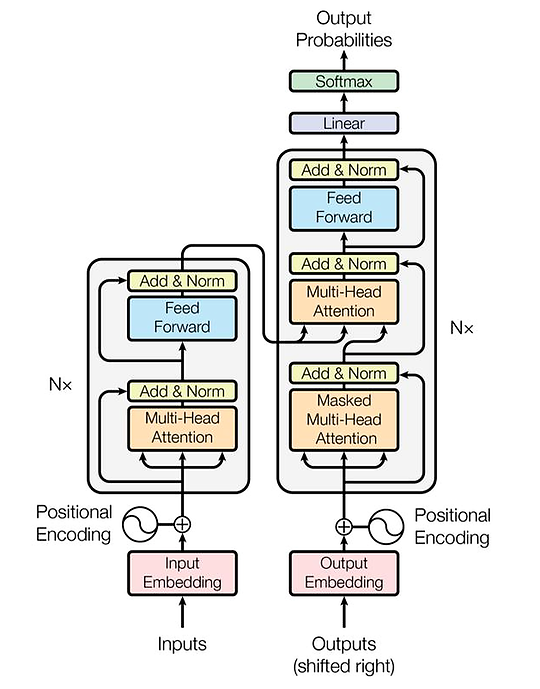

*출처: Vaswani et al. (2017), **Attention Is All You Need**, Figure 1.*

처음부터 모든 상자와 화살표를 이해할 필요는 없다. 먼저 다음의 전체 처리 흐름을 살펴보자.

**입력 임베딩**(Input Embedding) → **Encoder** → **Decoder** → **출력 확률**(Output Probabilities)

이후 토큰화, 임베딩, 위치 인코딩, Attention을 차례로 배우고, 뒤에서 이 그림을 다시 확인한다.


---
# 텍스트는 어떻게 Transformer의 입력이 되는가?

Transformer는 글자 자체를 계산하지 않는다. 문장을 **토큰**(Token)으로 나누고, 토큰에 정수 번호를 부여한 뒤, 각 번호에 대응하는 실수 벡터를 사용한다. 이 벡터에 **위치 정보**를 반영하면 Transformer에 입력할 숫자 표현이 준비된다.

이 절에서는 하나의 문장을 끝까지 사용한다.

> **공통 예문:** `The unbelievable red car is fast.`

수업용 가정은 **단어 기준 7개 토큰, ID 10~16, 어휘집 10000종류, 임베딩 256차원**이다. 이 숫자들은 계산 관계를 보여주기 위한 설정이며, 실제 모델은 자체 토크나이저와 가중치를 갖는다.

```text
문장 → 표준화 → 토큰화 → 어휘집에서 토큰 ID 조회
                              ↓
                  임베딩 테이블에서 벡터 조회
                              ↓
                      위치 정보 결합
                              ↓
                       Transformer
```


## 텍스트 표준화: 왜 필요할까?

**텍스트 표준화**(Text Standardization)는 입력 텍스트의 띄어쓰기, 대소문자, 문장부호 등 표기 방식이 다를 때, **미리 정한 규칙에 따라 표현을 일관되게 정리하는 과정**이다. 데이터의 특성과 모델에 따라 적용하는 규칙은 다르다.

공통 문장이 복사 과정에서 다음처럼 들어왔다고 하자.

```text
표준화 전: "  The   unbelievable  red car is fast.  "
표준화 후: "The unbelievable red car is fast."
```

이 예제에서는 (a) 앞뒤 공백을 제거하고 (b) 연속된 공백을 하나로 합친다. 코드로는 다음과 같다.

```python
import re
raw_text = "  The   unbelievable  red car is fast.  "
text = re.sub(r"\s+", " ", raw_text.strip())
print(text)
```

다른 표준화 규칙도 가능하다. 예를 들어 소문자화하면 `the unbelievable red car is fast.`로 바뀌고, 문장부호를 제거하면 마침표도 사라진다. 그러나 이런 변화는 뒤에서 만들 **토큰과 ID에 영향을 줄 수 있으므로**, 여기서는 대문자 `The`와 마침표 `.`를 그대로 유지한다.

**모든 모델에 공통인 표준화 규칙은 없다.** 이미 학습된 모델을 사용할 때는 임의로 표준화하기보다 **그 모델과 함께 제공되는 토크나이저**의 규칙을 따른다.


## 토큰화: 같은 문장을 여러 방식으로 나누기

**토큰화**(Tokenization)는 텍스트를 모델이 처리할 작은 단위인 **토큰**으로 나누는 과정이다. 토큰은 단어, 단어의 일부, 문장부호일 수 있다.

| 토큰화 방법 | 공통 문장을 나눈 결과 | 토큰 수 |
|---|---|---:|
| **단어 단위**(Word-level) | `The` / `unbelievable` / `red` / `car` / `is` / `fast` / `.` | 7 |
| **부분단어 단위**(Subword-level) | `The` / `un` / `believ` / `able` / `red` / `car` / `is` / `fast` / `.` | 9 |

**부분단어**(Subword)는 단어보다 작은 토큰 조각이다. 긴 단어나 드문 단어를 작은 조각으로 표현할 수 있다는 장점이 있다. 다만 위의 `un` / `believ` / `able`은 **개념 설명용 가상 분할**이며, 실제 모델이 이렇게 나누는지는 해당 토크나이저에 달려 있다. 부분단어는 언어학적 형태소와 반드시 일치하지 않는다.

이후의 수업용 ID와 임베딩 설명은 첫 번째 줄의 **7개 토큰**만 사용한다. 부분단어 방식은 동일한 예문에 대해 토큰화 결과가 어떻게 달라질 수 있는지 비교하기 위한 것이다.


## 어휘집은 무엇이며 어떻게 만들어질까?

**어휘집**(Vocabulary)은 **모델이 구분할 토큰 종류와 각 토큰에 대응하는 정수 ID를 모아 놓은 표**다. 텍스트가 입력될 때마다 새로운 어휘집을 만드는 것이 아니라, 보통 모델을 준비하는 과정에서 어휘집을 만들고 저장하여 일관되게 사용한다.

어휘집을 만드는 일반적인 흐름은 다음과 같다.

1. 모델 학습에 사용할 많은 텍스트를 모으고 표준화 규칙을 정한다.
2. 토큰 후보들을 수집한다. **단어 기준**이라면 각 단어의 등장 빈도를 셀 수 있다. **부분단어 기준**이라면 여러 문자·부분 문자열이 함께 등장하는 패턴을 학습하는 알고리즘을 사용할 수 있다.
3. 어휘집 크기와 특수 토큰을 정한다. 예컨대 어휘집 크기를 **10000개**로 정하면, 선택한 방식으로 토큰 종류 10000개를 구성한다.
4. 각 토큰에 고유한 ID를 부여하고, 어휘집과 토크나이저를 저장한다. 이후 새 문장에도 같은 규칙을 적용한다.

따라서 **어휘집 크기가 10000**이라는 말은 *한 문장의 토큰 수가 10000개*가 아니라, **구별 가능한 토큰의 종류가 10000개**라는 뜻이다. 실제 크기는 모델마다 다르다.

이번 예제에서는 전체 10000개 중 공통 문장에 필요한 일부 항목만 다음과 같이 가정한다.

| 토큰 | `[PAD]` | `[UNK]` | `The` | `unbelievable` | `red` | `car` | `is` | `fast` | `.` |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| **수업용 ID** | 0 | 1 | **10** | **11** | **12** | **13** | **14** | **15** | **16** |

`[PAD]`는 필요할 때 채움용으로 사용할 토큰이고, `[UNK]`는 단어 단위 어휘집에서 등록되지 않은 토큰을 표시하는 데 사용할 수 있다. 부분단어 토크나이저는 낯선 단어를 알려진 조각으로 분해하기도 한다.

```text
토큰   : [The, unbelievable, red, car, is, fast, .]
토큰 ID: [ 10,           11,  12,  13, 14,   15, 16]
```

ID는 토큰의 **식별 번호**일 뿐 의미를 나타내는 수치가 아니다. `red=12`, `car=13`이라고 해서 두 토큰의 의미가 비슷하다는 뜻은 아니다. 이 번호들은 설명을 위해 임의로 정한 것이며 실제 모델과 다를 수 있다.


## 임베딩 테이블에서 벡터를 조회하기

토큰 ID만으로는 토큰 사이의 언어적 관계를 표현하기 어렵다. Transformer는 토큰을 여러 개의 실수로 나타낸 **임베딩 벡터**(Embedding Vector)를 사용한다. 여기서는 **토큰 하나를 실수 256개로 표현**한다고 가정한다.

**임베딩 테이블**(Embedding Table)은 ID별 임베딩 벡터를 저장한 표다. 어휘집에 10000개 토큰이 있고 토큰 하나를 256개 숫자로 나타내면, 임베딩 테이블에는 10000개 행과 256개 열이 있다.

| 배열 | 행 수 | 열 수 | 모양 |
|---|---:|---:|---|
| 전체 임베딩 테이블 | 10000 | 256 | `(10000, 256)` |
| 이번 문장의 임베딩 | 7 | 256 | `(7, 256)` |

우리 문장의 ID 배열은 `[10, 11, 12, 13, 14, 15, 16]`이다. 따라서 전체 테이블을 복사하지 않고 **10, 11, 12, 13, 14, 15, 16번 행만 꺼낸다.**

```text
전체 임베딩 테이블 E : (10000, 256)

E[10] → The          의 256차원 벡터
E[11] → unbelievable 의 256차원 벡터
E[12] → red          의 256차원 벡터
E[13] → car          의 256차원 벡터
E[14] → is           의 256차원 벡터
E[15] → fast         의 256차원 벡터
E[16] → .            의 256차원 벡터

7개 벡터를 행으로 쌓은 결과 : (7, 256)
```

토큰 하나에 대응하는 벡터의 길이는 256으로 일정하지만, **문장의 토큰 수는 달라질 수 있다.** 아래 그림은 일곱 개의 벡터를 7행×256열로 배열한 모습을 나타낸다.


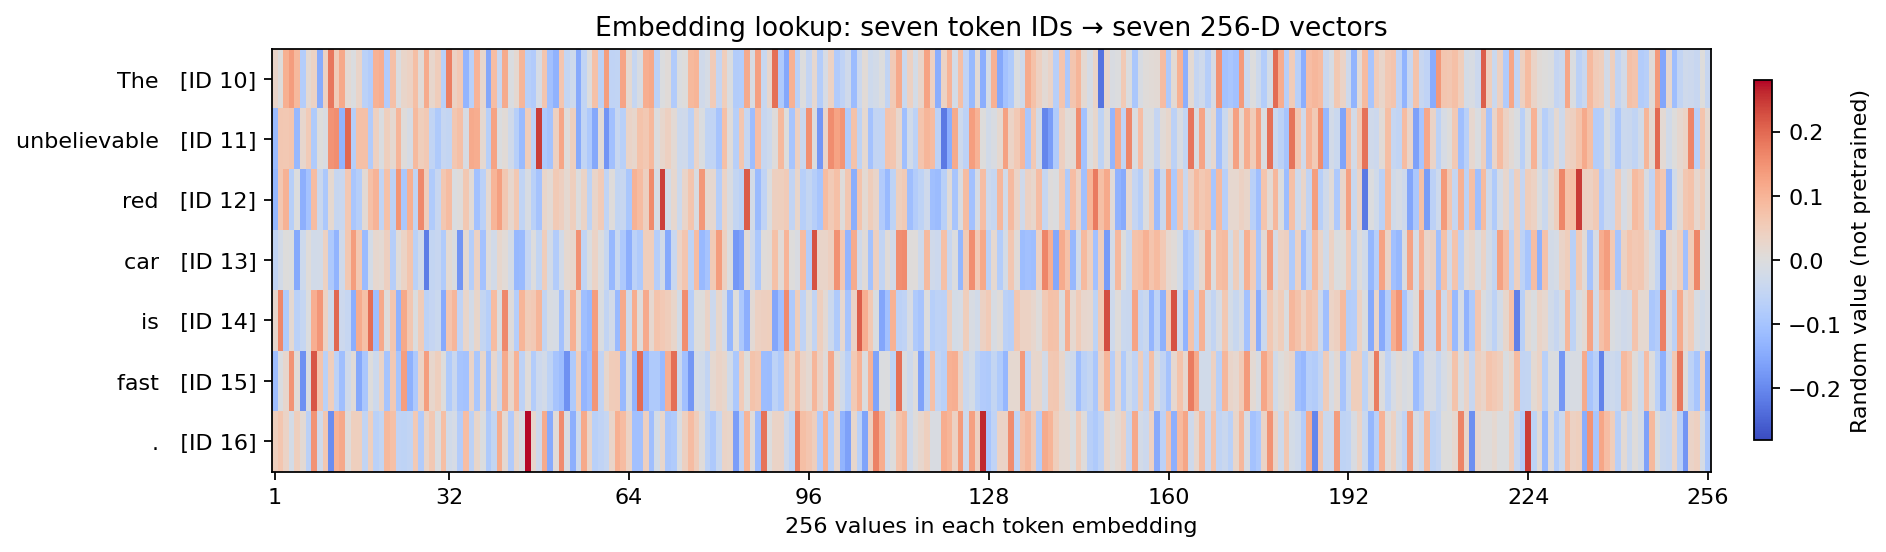

*한 행은 한 토큰의 벡터이고 열은 벡터의 성분이다. 그림의 숫자는 임베딩 테이블의 초기값을 예시한 것으로, 아직 언어를 학습한 결과가 아니다.*


## 임베딩 테이블의 숫자는 어떻게 학습될까?

앞에서는 어휘집의 토큰 ID를 사용해 임베딩 테이블의 특정 행을 조회하는 과정을 살펴보았다. 그렇다면 **각 행에 있는 256개 숫자는 어떻게 정해질까?**

임베딩 테이블은 모델이 사용하는 **가중치**(Weight)의 일부다. 가중치는 모델의 계산에 사용되는 숫자로, 학습 과정에서 값이 조정될 수 있다.

일반적으로 모델을 처음 만들 때는 임베딩 테이블에 작은 무작위 숫자를 넣어 **초기화**한다. 이 단계의 `car` 벡터가 이미 자동차의 의미를 알고 있는 것은 아니다. 그런 정보가 유용하게 표현되려면 학습 과정이 필요하다.

학습은 다음과 같은 흐름으로 진행된다.

1. 모델에 학습 데이터를 입력한다.
2. 모델이 주어진 **학습 과제**에 대해 결과를 예측한다.
3. 그 예측을 학습 데이터의 정답과 비교해 **오차**를 계산한다.
4. 오차가 작아지도록 임베딩을 포함한 여러 가중치를 조금씩 조정한다.
5. 많은 학습 사례에 대해 이 과정을 반복한다.

따라서 임베딩은 **사람이 토큰별로 의미를 정해 입력한 표가 아니라, 다른 가중치와 함께 학습되는 숫자들의 표**다. 학습된 벡터의 256개 좌표가 각각 색깔이나 속도처럼 하나의 정해진 뜻을 갖는 것도 아니다. 여러 값이 함께 작용하면서 언어 처리에 유용한 표현이 만들어진다.

앞의 임베딩 그림은 **초기화된 테이블의 모양을 보여주는 예시**다. 다음으로, 실제로 어떤 예측 과제를 통해 이 숫자들을 학습할 수 있는지 살펴보자.


## 언어 모델은 어떤 과제로 학습할까?

방금 살펴본 학습 과정에서 모델은 **무엇을 예측해야 할까?** 이는 모델의 용도에 따라 다르다. 여기서는 대표적인 예로 **언어 모델**(Language Model)을 살펴보자.

언어 모델은 텍스트에 나타나는 토큰들의 연결 패턴을 학습한다. 특히 **생성형 언어 모델**은 앞에 나온 토큰들을 바탕으로 **다음 토큰을 예측**하는 과제로 학습할 수 있다. 학습 문장 자체에서 다음 토큰을 정답으로 정할 수 있다.

공통 예문 `The unbelievable red car is fast.`를 사용하면 다음과 같은 학습 사례를 만들 수 있다.

| 모델에 입력하는 앞부분 | 실제 다음 토큰(정답) |
|---|---|
| `The` | `unbelievable` |
| `The unbelievable` | `red` |
| `The unbelievable red` | `car` |
| `The unbelievable red car` | `is` |
| `The unbelievable red car is` | `fast` |
| `The unbelievable red car is fast` | `.` |

가령 모델이 `The unbelievable red` 다음에 `car`가 나올 확률을 낮게 예측했다면, 정답과 예측 사이에 오차가 발생한다. 이 오차를 줄이기 위해 **임베딩 테이블과 Attention 등 모델의 가중치가 함께 조정**된다. 같은 과정을 수많은 문장에 반복하면 토큰의 임베딩도 점차 학습된다.

여기서 중요한 점은 **다음 토큰 예측이 임베딩만을 위한 별도 학습이 아니라, 언어 모델 전체를 학습하는 과제**라는 것이다. 임베딩 테이블은 그 과정에서 함께 바뀌는 여러 가중치 중 하나다.


## 이미 학습된 모델은 어떻게 사용하는가?

지금까지는 모델을 **처음 만들고, 학습을 통해 가중치를 조정하는 과정**을 설명했다. 하지만 실제 응용에서는 이 과정을 매번 처음부터 반복하지 않고, **이미 학습을 마친 모델의 가중치를 불러와 사용**하는 경우가 많다.

특히 대량의 텍스트로 언어의 일반적인 패턴을 먼저 학습하는 단계를 **사전훈련**(Pretraining)이라고 한다. 앞에서 본 다음 토큰 예측은 생성형 언어 모델의 대표적인 사전훈련 방법이다. 이렇게 학습된 모델은 이후 다른 작업에 활용하거나, 필요하면 특정 작업에 맞게 추가 학습할 수 있다.

**사전훈련된 모델**(Pretrained Model)을 불러온다는 것은 단순히 어휘집이나 임베딩을 새로 만드는 것이 아니라, **임베딩 테이블과 Attention 층 등 이미 학습된 가중치**를 가져오는 것이다. 따라서 같은 토큰 ID를 조회해도 임의로 초기화한 테이블에서 가져온 벡터와, 학습을 마친 테이블에서 가져온 벡터의 값은 다르다.

다만 모든 모델이 **다음 토큰 예측이라는 동일한 과제로 학습된 것은 아니다.** 예를 들어 영어→스페인어 번역 모델은 영어 입력과 스페인어 번역문의 짝을 이용해 학습할 수 있다. 모델의 종류에 따라 학습 과제가 다르지만, 학습된 가중치를 저장한 뒤 새 입력에 활용한다는 원리는 같다.

이번 **P4 Lab**에서는 다음을 구분하여 확인한다.

- **임베딩 구조 관찰:** `(10000, 256)` 모양의 테이블을 임의의 숫자로 만든 뒤 ID에 맞는 행을 조회한다. 이 테이블은 학습된 가중치가 아니다.
- **사전훈련 모델 활용:** 이미 학습된 번역 모델을 불러와 임베딩 가중치를 살펴보고, 새로운 영어 문장을 스페인어로 번역한다. **가중치를 다시 학습하지 않는다.**

이후 Decoder-only 언어 생성과 Project에서도 같은 방식으로 **학습을 마친 모델을 불러와 추론에 사용**한다.


## 새 문장이 들어오면 길이를 어떻게 처리할까?

**어휘집 크기**와 **임베딩 차원**은 모델에서 정해져 있지만, 실제로 입력받는 문장의 **토큰 수는 매번 달라질 수 있다.** 문장을 토큰화한 뒤 그 개수만큼 임베딩 행을 조회하면 된다.

| 입력 | 토큰 ID | 임베딩 모양 |
|---|---|---|
| 공통 문장 전체 | `[10, 11, 12, 13, 14, 15, 16]` | `(7, 256)` |
| 공통 문장의 앞부분 `The unbelievable red car` | `[10, 11, 12, 13]` | `(4, 256)` |

**최대 입력 길이**는 모델이 한 번에 처리할 수 있도록 지원하는 상한이다. 예를 들어 가상의 모델이 최대 512토큰을 처리할 수 있다고 해도 7개짜리 문장을 항상 512개 길이로 만들 필요는 없다.

### 여러 문장을 하나의 배치로 묶는 경우

서로 길이가 다른 입력을 **같은 크기의 배열**에 묶으려면 짧은 입력에 **패딩**(Padding)이라는 채움용 토큰을 붙이기도 한다. 아래는 7개짜리 문장과 앞부분 4개를 함께 처리하는 경우다.

```text
원래 A: [10, 11, 12, 13, 14, 15, 16]
원래 B: [10, 11, 12, 13]

배치의 가장 긴 입력에 맞춰 길이를 7로 정하면:
입력 A: [10, 11, 12, 13, 14, 15, 16]
입력 B: [10, 11, 12, 13,  0,  0,  0]
                             ↑ 0은 [PAD]에 해당
```

이 경우 **배치에 맞춘 길이 7**은 모델의 **최대 허용 길이와 별개**다. 다른 입력들을 묶으면 배치 길이가 달라질 수 있지만 모델이 지원하는 최대 길이가 변하는 것은 아니다. 한 문장만 입력하거나 가변 길이를 지원하는 계산 방법을 사용하면 패딩이 필요하지 않을 수도 있다.

패딩으로 추가한 위치는 원래 문장의 정보가 아니므로 **Attention 계산에서 실제 토큰처럼 참고하면 안 된다.** 이를 구별하는 표식을 **패딩 마스크**(Padding Mask)라고 한다. 이번 예시에서는 `1=실제 토큰`, `0=패딩`으로 약속한다.

```text
A의 패딩 마스크: [1, 1, 1, 1, 1, 1, 1]
B의 패딩 마스크: [1, 1, 1, 1, 0, 0, 0]
```

**패딩은 길이를 맞추고, 마스크는 채움용 위치를 구별한다.** 마스크 값의 약속은 라이브러리에 따라 달라질 수 있다. 뒤에서 배우는 **Causal Mask**는 미래의 출력 토큰을 보지 못하게 한다는 점에서 목적이 다르다.

따라서 이 배치의 ID 배열은 `(2, 7)`이고, 임베딩 배열은 `(2, 7, 256)`이다. 순서대로 입력 두 개, 배치에서 맞춘 길이 7, 토큰당 256개 실수를 뜻한다.


## 위치 인코딩: 단어의 순서를 어떻게 알려줄까?

임베딩 테이블에서 `car`의 벡터 `E[13]`을 가져왔다고 하자. 이것은 **어떤 토큰인가**를 나타내지만, 그 토큰이 **문장의 몇 번째 위치에 있는지**까지 알려주지는 않는다. 원래 Transformer는 이를 위해 **위치 인코딩**(Positional Encoding)을 사용했다.

| 위치 번호 $p$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| 토큰 | `The` | `unbelievable` | `red` | `car` | `is` | `fast` | `.` |
| ID | 10 | 11 | 12 | 13 | 14 | 15 | 16 |

### 위치 번호를 256개의 숫자로 바꾸기

원래 Transformer에서는 **사인·코사인 함수**를 이용해 위치 $p$마다 길이 256인 벡터 $P[p]$를 계산한다. 이 방식은 **위치 벡터의 숫자를 훈련으로 학습하지 않는다.** 위치 번호와 차원 번호만 알면 정해진 공식으로 계산한다.

첫 번째와 두 번째 성분은 다음과 같다.

$$
P[p,0]=\sin(p), \qquad P[p,1]=\cos(p)
$$

그렇다면 나머지 성분은 무엇일까? **같은 사인·코사인이지만 위치가 바뀔 때 숫자가 변하는 속도를 달리**한다. 예를 들어 차원이 256이라면 65번째와 66번째 성분(인덱스 64, 65)은 다음처럼 계산한다.

$$
P[p,64]=\sin(p/10), \qquad P[p,65]=\cos(p/10)
$$

129번째와 130번째 성분(인덱스 128, 129)은 각각 $\sin(p/100)$, $\cos(p/100)$으로 계산한다. 즉 **앞부분 성분은 빠르게 변하고, 다른 성분은 천천히 변한다.** 이 다양한 숫자 패턴을 조합하면 각 위치의 벡터를 구별할 수 있다.

| 위치 $p$ | $\sin(p)$ | $\cos(p)$ | $\sin(p/10)$ | $\cos(p/10)$ | $\sin(p/100)$ |
|---:|---:|---:|---:|---:|---:|
| 0 | 0.000 | 1.000 | 0.000 | 1.000 | 0.000 |
| 1 | 0.841 | 0.540 | 0.100 | 0.995 | 0.010 |
| 3 | 0.141 | -0.990 | 0.296 | 0.955 | 0.030 |
| 6 | -0.279 | 0.960 | 0.565 | 0.825 | 0.060 |

이 표는 전체 256개 숫자 가운데 다섯 개만 보여준다. 나머지 성분도 서로 다른 주기의 사인·코사인 값으로 채운다. Lab에서는 이 차이를 그래프로 확인한다.

### 임베딩과 위치 벡터를 결합하기

**$d_{\mathrm{model}}$**은 Transformer 내부에서 한 토큰을 표현하는 **벡터 차원**을 뜻한다. 이번 예제에서는 $d_{\mathrm{model}}=256$이다. 토큰 임베딩과 위치 벡터의 길이가 모두 256이므로 **같은 성분끼리 더할 수 있다.** 원래 Transformer는 임베딩에 $\sqrt{d_{\mathrm{model}}}$을 곱한 후 위치 벡터를 더한다.

$$
\mathbf{x}_p = \sqrt{d_{\mathrm{model}}}\,E[\mathrm{ID}_p]+P[p]
$$

예를 들어 위치 3의 `car`는 `E[13]`에 `P[3]`을 더한다. 벡터를 옆으로 이어 붙여 512차원으로 만드는 것이 아니라 **같은 자리의 숫자를 더하므로 256차원 그대로**다.

| 배열 | 모양 |
|---|---|
| 토큰 일곱 개의 임베딩 | `(7, 256)` |
| 위치 0~6의 벡터들 | `(7, 256)` |
| 두 벡터들을 성분별로 결합한 입력 | `(7, 256)` |

### 위치 벡터도 학습될까?

**원래 Transformer의 사인·코사인 위치 인코딩은 학습하지 않는다.** 같은 모델 설정에서는 어떤 문장이 들어와도 **위치 번호에 따라 위치 벡터가 정해진다.** 예를 들어 위치 0에는 `P[0]`, 위치 1에는 `P[1]`을 계산한다. 다만 실제 단어 앞에 특수 토큰이 추가되면 그 단어에 배정되는 위치 번호가 달라질 수 있다.

반면 **다른 모델들은 위치별 벡터를 가중치처럼 학습**하기도 한다. 현대 LLM에는 RoPE 같은 다른 위치 표현 방법도 쓰인다. 위치 정보를 표현하는 방법은 여러 가지지만, 여기서는 **원래 Transformer가 숫자 패턴으로 토큰의 순서를 전달한다는 원리**가 중요하다.


## 토큰 임베딩과 문맥 표현은 다르다

같은 모델의 가중치가 고정되어 있다면 `car`의 ID는 항상 `13`이고, 임베딩 테이블에서 같은 `E[13]`을 가져온다. 그러나 `car`가 문장에서 놓인 위치가 달라지면 **더해지는 위치 벡터**가 달라진다. 그리고 다음 절의 **Self-Attention**을 거치면서 주변 토큰의 정보가 반영된다.

따라서 다음 세 가지는 구분해야 한다.

- **토큰 ID:** 어휘집의 식별 번호
- **토큰 임베딩:** 임베딩 테이블에서 가져온 벡터
- **문맥을 반영한 표현:** 위치 정보와 Attention 등의 계산을 거친 벡터

앞에서는 텍스트를 계산 가능한 숫자로 바꾸었다. 이어지는 Attention에서는 이 숫자들이 **다른 토큰의 정보를 어떻게 반영하는지** 살펴본다.


## 텍스트 입력 과정 정리

```text
"  The   unbelievable  red car is fast.  "
                  ↓  표준화
The unbelievable red car is fast.
                  ↓  단어 단위 토큰화
[The, unbelievable, red, car, is, fast, .]     7개 토큰
                  ↓  어휘집에서 ID 조회
[10, 11, 12, 13, 14, 15, 16]              (7,)
                  ↓  임베딩 테이블 (10000, 256)에서 7개 행 조회
토큰 임베딩 벡터                            (7, 256)
                  ↓  위치 0~6에 해당하는 위치 벡터 결합
Transformer 입력                           (7, 256)
```

**핵심:** 어휘집은 **토큰 종류의 목록**, ID는 **식별 번호**, 임베딩은 **학습 가능한 실수 벡터**다. 원래 Transformer의 사인·코사인 위치 벡터는 **학습하지 않고 계산**하며, 학습된 모델을 불러오면 이미 조정된 임베딩·Attention 가중치를 그대로 사용할 수 있다.

**확인 질문:** 어휘집은 어떻게 만들어지는가? `(10000, 256)`과 `(7, 256)`은 왜 다른가? 임베딩 표의 숫자는 언제 바뀌는가? 위치 `P[0]`의 숫자는 어떤 문장이 들어오든 같은가?


---
# 단어 사이의 관계를 어떻게 파악하는가? — Self-Attention과 Q·K·V

앞에서 `The unbelievable red car is fast.`를 **7개 토큰**, 각 **256차원 벡터**로 나타냈다. 이제 이 토큰들이 **서로 정보를 참고해 문맥에 맞는 표현으로 바뀌는 과정**을 살펴보자.

예를 들어 `car`라는 토큰의 표현을 만들 때 `red`(색깔)와 `fast`(자동차의 속도에 관한 서술) 같은 주변 토큰 정보가 도움이 될 수 있다. Self-Attention은 **어떤 토큰을 얼마만큼 참고할지 계산해 다른 토큰의 정보를 섞는 방법**이다.


## Q·K·V는 각 토큰의 역할이 아니라 '정보를 계산하는 세 벡터'다

| 구분 | 역할 | 직관적인 질문 |
|---|---|---|
| **Q**(Query) | 현재 토큰이 찾는 정보의 조건 | `car`를 표현하려면 어떤 정보를 참고하면 될까? |
| **K**(Key) | 각 토큰이 제공하는 정보의 비교용 표지 | `red`, `fast` 등이 `car`의 요구와 얼마나 관련될까? |
| **V**(Value) | 실제로 가중합하여 가져올 정보 | 참고할 토큰의 정보 중 얼마나 반영할까? |

Q·K·V는 '단어를 셋으로 나눈다'는 뜻이 아니다. **모든 토큰 표현에서 Q·K·V를 각각 계산**한다. 실제 Transformer는 학습된 세 종류의 변환 행렬을 사용한다.

1. 현재 토큰의 Q를 다른 토큰들의 K와 비교하여 **관련성 점수**를 얻는다.
2. 점수를 **Softmax**로 변환하여 합이 1인 **Attention 가중치**를 얻는다.
3. 각 토큰의 V에 가중치를 곱해 더한다. 이것이 **현재 토큰에 반영될 문맥 정보**가 된다.

아래의 숫자는 원리 확인용으로 **인위적으로 설계한 값**이다. 실제 사전훈련 모델의 Attention을 추출한 결과가 아니다.


## 같은 문장의 7개 토큰에 Attention을 적용하면

수업용 ID `[10, 11, 12, 13, 14, 15, 16]`에 대응하는 벡터를 `(7, 256)`으로 준비했다고 하자. 여기서는 `car`(네 번째 토큰)가 `red`와 `fast`에 더 큰 가중치를 주도록 예제 Q·K를 설정한다.

| `car`가 참고하는 토큰 | The | unbelievable | red | car | is | fast | . |
|---|---:|---:|---:|---:|---:|---:|---:|
| **Attention 가중치**(교육용) | 0.047 | 0.047 | **0.344** | 0.126 | 0.047 | **0.344** | 0.047 |

표의 값은 반올림했으므로 합이 1과 약간 다르게 보일 수 있다. 원래 계산에서는 **정확히 1**이다.

`car`의 새 정보는 `red`와 `fast`의 **V 벡터**에 큰 비중을 주고, 나머지 토큰의 V도 해당 가중치만큼 섞어 얻는다. **어떤 토큰을 더 참고할지**가 중요하며 학생이 256개 숫자를 일일이 계산할 필요는 없다.


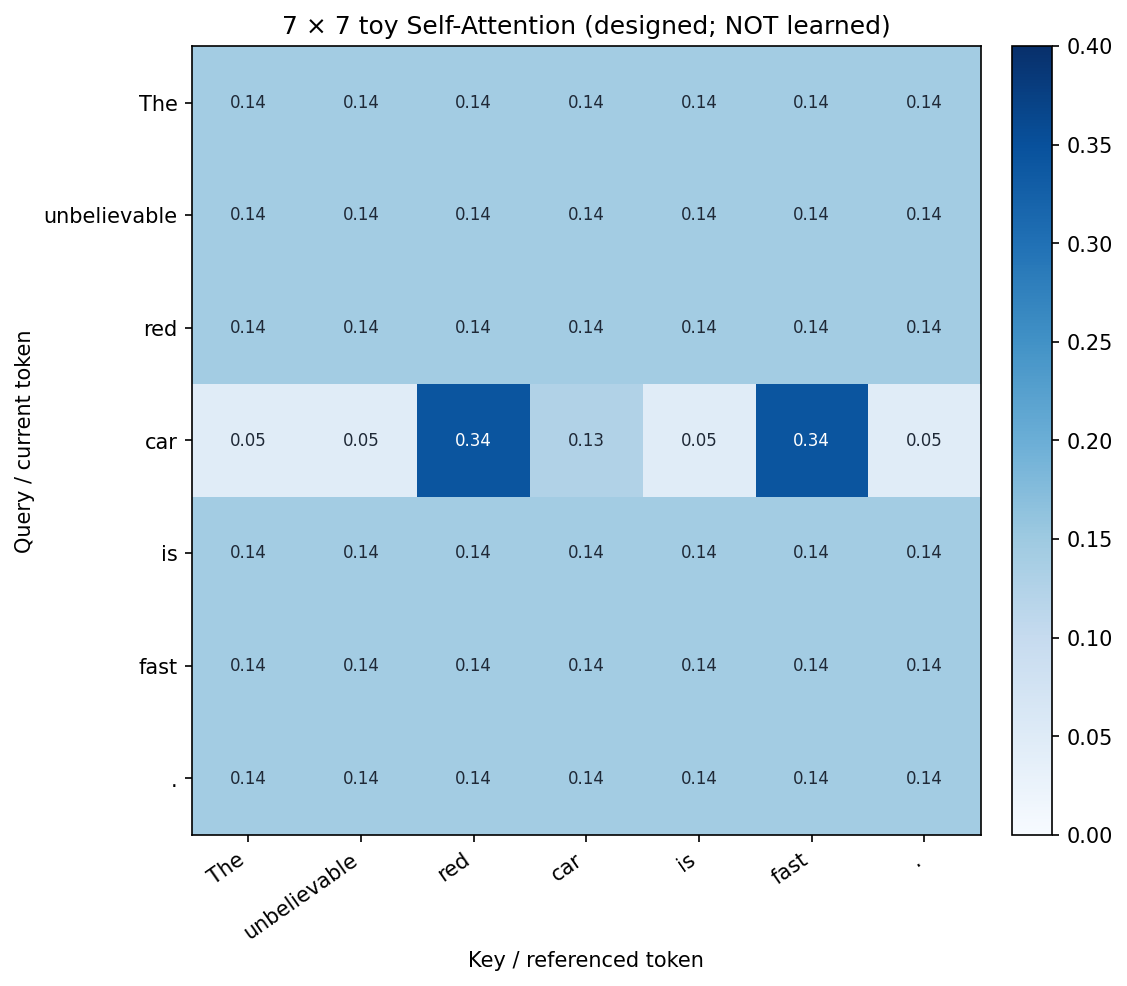

*그림: 행은 현재 토큰(Query), 열은 참고하는 토큰(Key)이다. `car` 행에서 `red`와 `fast`의 가중치가 높게 보이도록 **교육용 Q·K 값을 설정**했다. 다른 토큰 관계를 학습한 실제 모델 결과는 아니다.*


## 왜 Attention 표는 7×7인데 결과는 7×256일까?

| 단계 | 배열 모양 | 의미 |
|---|---|---|
| 입력 X | `(7, 256)` | 7개 토큰의 256차원 표현 |
| Q, K, V | 각각 `(7, 256)` | 하나의 Head를 단순화한 설정 |
| Q와 K의 관련성 점수 | `(7, 7)` | **7개 토큰 각각이 나머지 7개를 얼마나 참고할지** |
| Softmax 가중치 | `(7, 7)` | 행별 가중치 합이 1 |
| 가중치 × V | `(7, 256)` | 각 토큰에 문맥 정보가 반영된 256차원 표현 |

Attention은 임베딩 차원을 7차원으로 줄이는 작업이 아니다. **7×7 가중치 표로 어떤 토큰의 정보를 얼마나 반영할지 결정**하고, 그 결과를 **256차원 벡터들에 적용**하는 과정이다.

원리를 한 줄로 쓰면 다음과 같다.

$$
\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\left(\frac{QK^{\mathsf T}}{\sqrt{d_k}}\right)V
$$

이 수식의 의미는 **Q·K로 가중치를 정하고 V를 가중합한다**는 것이다. 자세한 행렬 계산은 이번 수업에서 요구하지 않는다.


## Multi-Head Attention은 왜 사용할까?

단일 Head가 관계를 한 가지 방식으로 계산한다면, 여러 Head는 **서로 다른 변환을 사용해 다양한 관계를 함께 계산**할 수 있다.

예를 들어 **토큰 표현 차원 256, Head 4개, Head당 차원 64**로 설계할 수 있다.

```text
입력 토큰 표현: 7 × 256
    ├─ Head 1 : 7 × 64 ─┐
    ├─ Head 2 : 7 × 64 ─┤
    ├─ Head 3 : 7 × 64 ─┼→ 이어 붙이기 → 7 × 256 → 출력 변환
    └─ Head 4 : 7 × 64 ─┘
```

다만 **모든 모델에서 Head 크기가 반드시 64인 것은 아니다.** 또한 특정 Head가 무조건 '색깔'이나 '문법'만 담당한다고 단정할 수 없다. 원래 Transformer 블록에는 Attention 외에도 **Feed Forward 층, 잔차 연결, 정규화** 등이 포함된다.


## Encoder와 Decoder가 사용하는 Attention은 어떻게 다를까?

| 종류 | Q의 출처 | K·V의 출처 | 참고 범위 |
|---|---|---|---|
| **Encoder Self-Attention** | 입력 토큰 | 같은 입력 토큰 | 앞뒤의 입력 토큰 모두 |
| **Decoder Masked Self-Attention** | Decoder의 현재 표현 | 이전 출력 표현 | 현재까지의 출력 토큰만 |
| **Cross-Attention** | Decoder 표현 | Encoder 출력 | 입력 문장의 정보를 참고 |

**Causal Mask**는 Decoder가 *미래에 생성될 출력 토큰*을 미리 참조하지 못하게 한다. 앞에서 본 **Padding Mask**(패딩 자리 제외)와는 목적이 다르다. 다음 장에서 영어 Encoder가 정보를 제공하고 스페인어 Decoder가 새 문장을 생성하는 방법을 연결한다.

**Attention 핵심 요약:** **Q·K는 어디를 참고할지 정하고, V는 실제로 가져올 정보**다. 7개 토큰의 Attention 가중치 표는 `(7, 7)`이지만, 출력된 표현은 `(7, 256)`이다.


---
# 원래 Transformer 아키텍처: Encoder + Decoder

2017년 *Attention Is All You Need*에서 제안한 Transformer는 **Encoder와 Decoder를 함께 사용**하는 구조였다. 입력 언어의 문장을 받아 다른 언어의 문장을 생성하는 기계 번역을 생각하면 이해하기 쉽다.

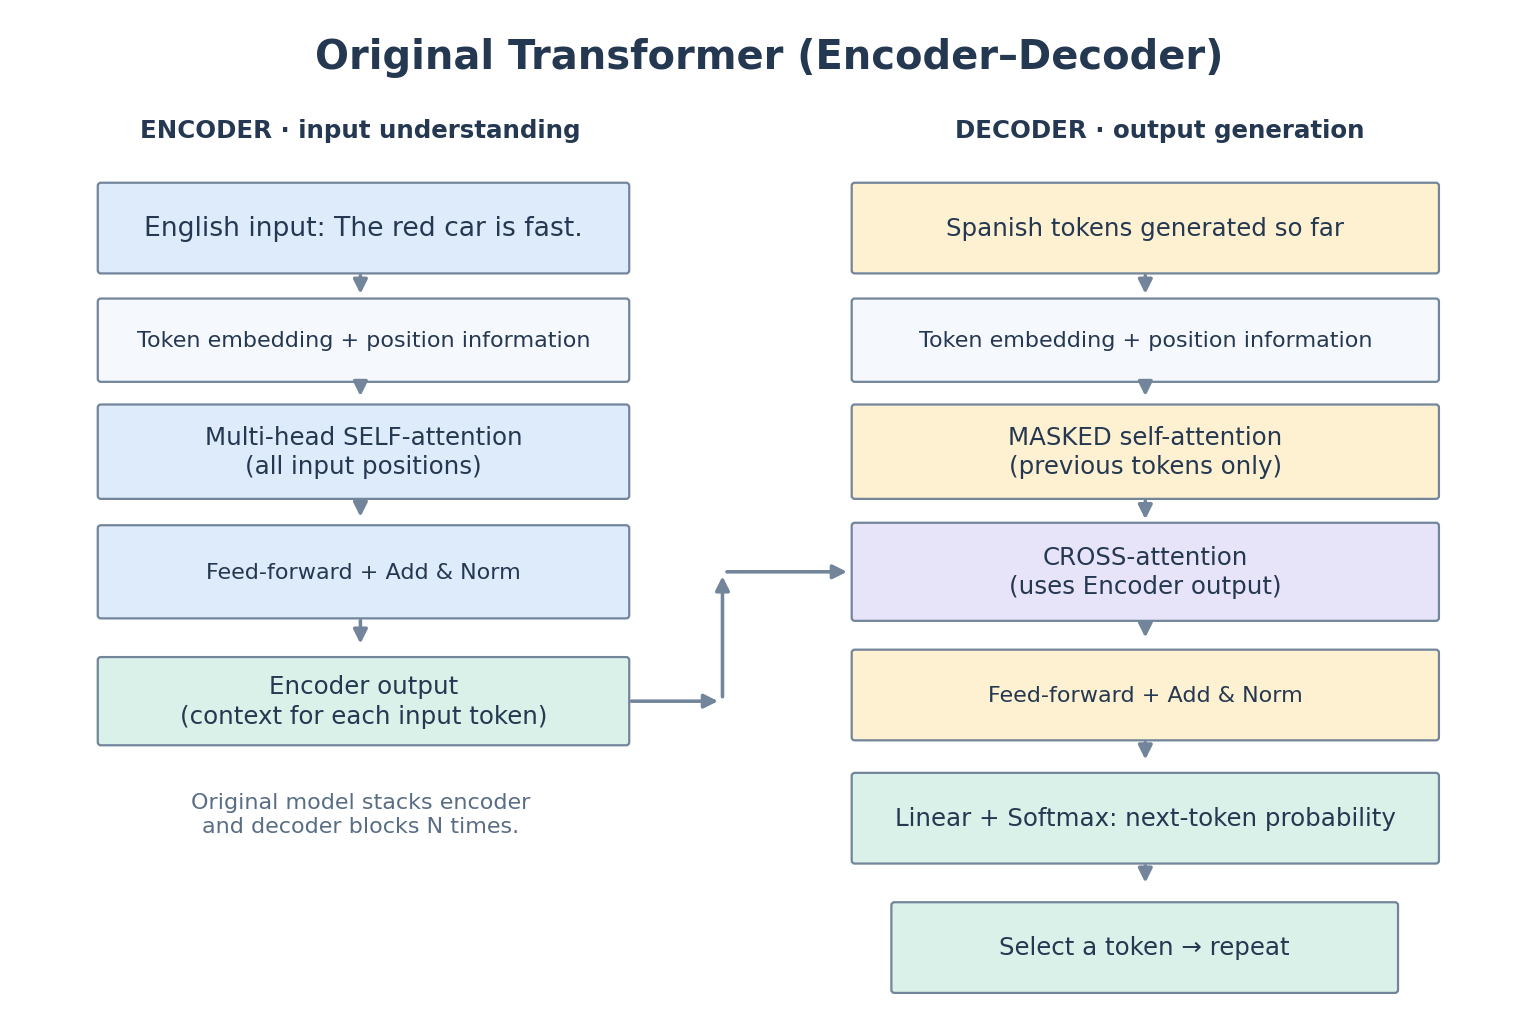

*그림: 원래 Transformer의 주요 블록과 연결을 학부 수준으로 단순화하여 새로 작성. Add & Norm, 반복 블록, 세부 경로 일부는 간략화하였다.*


## Encoder: 입력 문장 전체를 처리한다

예: **`The unbelievable red car is fast.`**

Encoder의 핵심 흐름:

1. 영어 문장을 토큰화하고 임베딩·위치 정보를 더한다.
2. **Self-Attention**으로 각 토큰이 다른 입력 토큰을 참고한다. 원래 Encoder의 Self-Attention은 입력 문장 앞뒤를 모두 참고할 수 있다.
3. Feed-Forward 등 추가 연산을 거쳐 **토큰별 문맥 표현**을 출력한다.

중요: Encoder는 문장을 **하나의 단어**나 **하나의 정수**로 바꾸는 것이 아니다. 여러 입력 토큰 각각에 대해 문맥이 반영된 벡터를 출력한다.

**핵심 질문:** Encoder의 목적은 영어 문장의 단어 순서를 스페인어 순서로 바로 바꾸는 것일까? → 아니다. 스페인어 생성을 돕는 입력 표현을 제공하는 것이다.


## Decoder: 앞서 생성한 단어와 입력 문장을 참고한다

Decoder에는 서로 다른 Attention이 두 번 등장한다.

| Decoder 단계 | 참고하는 정보 | 왜 필요한가? |
|---|---|---|
| **Masked Self-Attention** | 이미 생성된 스페인어 토큰들 | 미래에 아직 생성하지 않은 정답을 미리 보지 않기 위해 |
| **Cross-Attention** | Encoder가 만든 영어 문장의 표현 | 어떤 영어 내용을 번역하고 있는지 참고하기 위해 |
| 출력층 | Decoder가 계산한 표현 | 다음 스페인어 토큰의 확률 계산 |

원래 Transformer의 Decoder에는 이 두 Attention 외에도 Feed-Forward, 잔차 연결, 정규화가 포함된다. 지금은 **두 종류의 Attention이 무엇을 참고하는지**가 가장 중요하다.

### 왜 Causal Mask가 필요할까?

스페인어 단어를 왼쪽부터 하나씩 만든다면, 아직 생성하지 않은 오른쪽 단어를 미리 읽을 수 없어야 한다.

| 예측하려는 위치 | 볼 수 있는 출력 쪽 토큰의 예 | 아직 볼 수 없는 토큰 |
|---|---|---|
| 첫 토큰 | `[start]` | 모든 미래 스페인어 토큰 |
| 둘째 토큰 | `[start] El` | 그 뒤의 스페인어 토큰 |
| 셋째 토큰 | `[start] El coche` | 그 뒤의 스페인어 토큰 |

이때도 Decoder는 **Cross-Attention으로 영어 입력 전체를 참고**할 수 있다.


## 영어 → 스페인어 번역 예제

입력: **`The unbelievable red car is fast.`**

가능한 번역: **`El increíble coche rojo es rápido.`**

영어의 `red car`와 스페인어의 `coche rojo`는 단어 순서가 다르다. **영어와 스페인어를 같은 위치끼리 단순 대조하는 방식으로 번역하지 않는다.**

1. Encoder가 영어 문장 전체를 처리한다.
2. Decoder가 `[start]`에서 시작하여 다음 스페인어 토큰을 예측한다.
3. 선택한 토큰을 출력 쪽에 붙이고, 다음 토큰을 계속 예측한다.
4. 종료 토큰이 나오면 번역이 끝난다.

예를 들어:

```text
Encoder 입력: The unbelievable red car is fast.
Decoder 입력: [start]             → 다음 토큰: El
Decoder 입력: [start] El          → 다음 토큰: increíble
Decoder 입력: [start] El increíble → 다음 토큰: coche
Decoder 입력: [start] El increíble coche → 다음 토큰: rojo
...                               → 마지막 종료 토큰
```

여기서는 이해를 돕기 위해 출력 단위를 **단어처럼 표시**했다. 실제 Decoder는 모델의 토크나이저가 정의한 **토큰**(서브워드 포함)을 생성한다.

여기에서 `[start]`는 **설명용 표시**이며, 실제 사전훈련 모델의 시작·종료 토큰은 모델마다 다르다.

**주의:** 번역에는 여러 가지 자연스러운 표현이 존재한다. 모델이 생성한 문장을 유일한 정답으로 보지 않는다.


### '모델 훈련'과 '모델 사용'을 구분하자

이번 Lab에서는 번역 모델을 처음부터 훈련하지 않는다.

- **훈련:** 영어·스페인어 문장쌍을 이용하여 모델의 가중치를 조정하는 과정
- **사용(추론):** 이미 훈련된 모델에 **새로운 영어 문장**을 넣어 스페인어 번역을 생성하는 과정

원래 Transformer가 Encoder–Decoder 구조였다는 사실과, 실제 실습 모델이 **사전훈련된 Encoder–Decoder 계열**이라는 점을 연결하는 데 초점을 둔다.


## 원래 Transformer에서 LLM으로: 무엇이 달라졌을까?

앞에서는 **Encoder가 입력 문장을 처리하고, Decoder가 번역문을 생성하는 원래 Transformer**를 살펴보았다. 그런데 ChatGPT와 같은 생성형 언어 모델은 왜 별도의 Encoder 없이도 질문에 답하고 글을 쓸 수 있을까?

핵심은 **신경망의 구조**(아키텍처)와 **그 구조를 실제 데이터로 학습한 모델**을 구분하는 것이다.

- **Transformer:** Attention을 이용해 토큰 정보를 처리하는 *신경망 설계 방식*이다. 2017년에 제안된 원래 형태는 Encoder와 Decoder를 함께 사용했다.
- **Decoder-only Transformer:** 원래 구조에서 별도의 Encoder 및 Encoder와 연결하는 Cross-Attention 없이, 주로 **Causal Self-Attention**으로 앞선 토큰을 참고하며 다음 토큰을 예측하도록 만든 구조다. GPT 계열이 대표적이다.
- **LLM(Large Language Model):** 대규모 텍스트·코드 등의 데이터로 학습한 언어 모델을 말한다. 현대의 많은 생성형 LLM은 Decoder-only Transformer 기반이지만, **모든 LLM이 Decoder-only인 것은 아니다.**

### 모델이 문장을 생성할 수 있게 되는 과정

```text
Decoder-only Transformer 구조
       ↓
대규모 텍스트로 사전훈련(Pretraining)
: 앞선 토큰들을 보고 다음 토큰을 맞히도록 학습
       ↓
사전훈련된 언어 모델
       ↓
(선택적으로) 질문·답변 등의 예제로 추가 학습
       ↓
프롬프트를 받아 이어쓰기·질의응답 수행
```

예를 들어 `The capital of Spain is`라는 문장이 주어지면, 모델은 다음 토큰 후보들에 확률을 부여한다. 하나를 선택해 입력 뒤에 붙이고 **다음 토큰 예측을 반복**하면 문장이 생성된다. 이러한 원리는 번역 Decoder에서도 사용했지만, Decoder-only 모델에서는 **영어 입력을 처리하는 별도의 Encoder가 필요하지 않다.**

**기억할 점:** 다음 토큰 예측은 사전훈련의 주요 학습 목표이자 텍스트 생성의 핵심 원리다. 그러나 다음 토큰을 잘 예측하는 것과 **사실에 맞고 사용자의 지시를 잘 따르는 것**은 동일하지 않다. 지시문을 따르는 모델에는 추가 학습이 활용될 수 있으며, 이번 P4에서는 **학습 과정 자체를 구현하지 않고 사전훈련된 모델을 사용**한다.


## Transformer의 세 구조는 오늘날 어디에 사용할까?

원래 Transformer의 **Encoder와 Decoder를 함께 쓰는 방식** 외에도, 목적에 따라 한쪽만 사용하는 모델이 발전했다.

| 구조 | 대표 모델 | 현재의 주요 활용 | 학생들이 기억할 점 |
|---|---|---|---|
| **Encoder-only** | BERT, Sentence-BERT 계열 | 감성분석, 문서 분류, **의미 기반 검색** | 입력 텍스트를 분석하고 의미를 벡터로 표현한다. |
| **Encoder–Decoder** | MarianMT, T5, BART, Whisper | **번역**, 문서 요약, 음성 인식 | 입력을 처리한 뒤 다른 시퀀스를 생성한다. |
| **Decoder-only** | GPT, Llama 계열 | **텍스트 생성**, 질의응답, 코드 작성 | 프롬프트 뒤의 다음 토큰을 반복해서 예측한다. |

**간단한 사례:** 검색창에 `강아지를 키우는 방법`을 입력하면, Encoder 계열 임베딩 모델은 문장의 *의미*를 수치 벡터로 나타내어 `반려견 돌봄 안내`처럼 표현이 다른 관련 문서도 찾는 데 활용할 수 있다. 반면 번역 모델은 `The dog is sleeping.`을 스페인어 문장으로 변환하고, Decoder-only 모델은 `Once upon a time...` 뒤의 이야기를 계속 생성한다.

> **주의:** 이는 구조별 **대표적 활용**이지 엄격한 용도 구분은 아니다. Decoder-only 모델도 번역·요약을 할 수 있고, 모든 검색용 임베딩 모델이 Encoder-only인 것도 아니다. 이 P4 Lab에서는 **번역과 텍스트 생성**을 실습하고, P4 Project에서는 **Encoder 계열의 문서 검색**을 사용한다.


## Encoder-only: 문장 임베딩과 의미 검색

Encoder-only Transformer는 입력 문장을 **양방향 Self-Attention**으로 처리하여 문맥을 반영한 표현을 계산한다. BERT와 같은 인코더를 기반으로 만든 **문장 임베딩 모델**은 문장 전체를 하나의 벡터로 표현할 수 있다. (*BERT 자체의 모든 출력이 자동으로 문장 임베딩이 되는 것은 아니며, 문장 유사도에 적합하게 학습·구성된 모델을 사용한다.*)

예를 들어 `야생동물을 같은 개체로 중복 계산하지 않으려면?`이라는 질문을 받았다고 하자.

- 문서 A: `카메라에 같은 동물이 반복 등장하면 관측 횟수와 개체 수를 구분해야 한다.`
- 문서 B: `카메라 배터리는 매주 점검한다.`

문서 A에 질문과 **완전히 같은 단어가 없어도**, 의미가 비슷하면 검색 결과의 상위에 나타날 수 있다.

```text
질문 ------------------→ 문장 임베딩 모델 → 질문 벡터
문서 A, B, ... --------→ 문장 임베딩 모델 → 문서 벡터들
                                           ↓
                                  벡터의 유사도 비교
                                           ↓
                                  관련 문서 상위 3개
```

- **토큰 임베딩:** 한 토큰을 숫자 벡터로 나타낸다.
- **문장 임베딩:** 문장 또는 짧은 문서를 대표하는 하나의 숫자 벡터로 나타낸다.
- **의미 검색:** 질문 벡터와 문서 벡터의 유사도를 비교해 관련 문서를 찾는다. 흔히 **코사인 유사도**를 사용하지만, 이번에는 복잡한 수학적 계산 대신 *의미가 가까운 벡터를 찾는다*는 원리만 이해한다.

**주의:** 유사도가 높다는 것은 내용이 관련 있을 가능성이 높다는 뜻이지, **문서가 사실이라는 뜻은 아니다.**

## 두 구조의 협력: RAG(검색 증강 생성)

의미 검색만으로는 문서를 찾아 보여줄 수 있지만, 질문에 대한 **완성된 문장 형태의 답변**을 작성하지는 않는다. 반대로 Decoder-only 언어 모델에 질문만 넣으면 관련 문서를 확인하지 않고 답변을 생성할 수 있다.

**RAG**(Retrieval-Augmented Generation, 검색 증강 생성)는 이 두 과정을 연결한다.

```text
사용자 질문: "중복 관측 문제는 어떻게 해결하나요?"
                  ↓
① Encoder-only 기반 임베딩 모델
   → 질문과 관련된 문서 25개 중 상위 3개 검색
                  ↓
② 검색된 문서 3개 + 사용자 질문
   → Decoder-only 언어 모델에 함께 입력
                  ↓
③ 문서 내용에 근거한 답변 생성
   → 실제 근거와 일치하는지는 사람이 확인
```

| 단계 | 핵심 기능 | P4에서 사용하는 곳 |
|---|---|---|
| Encoder–Decoder | 입력 시퀀스를 다른 시퀀스로 변환 | **Lab:** 영어→스페인어 번역 |
| Encoder-only | 질문·문서를 벡터로 바꾸어 관련 문서 검색 | **Project:** 의미 검색 |
| Decoder-only | 검색된 문서를 참고하여 다음 토큰을 반복 생성 | **Project:** 답변 생성 |

**P4 Project 연결:** 사전에 준비한 **가상 '한솔 생태관측소' 안내 문서 25개**를 사용한다. 학생들은 *단어 일치 검색과 의미 검색*을 비교하고, 검색된 문서를 근거로 생성한 답변에 **문서에 없는 주장이 들어 있는지** 점검한다.

이 과정은 **모델을 새로 학습하지 않고**, 이미 학습된 모델 두 개를 연결해서 사용한다. RAG는 잘못된 답변을 줄이는 데 도움이 될 수 있지만 **항상 정확한 답을 보장하지는 않는다.**

---
# Decoder-only: Encoder 없이도 문장을 생성할까?

GPT 계열처럼 **Decoder만 여러 층 쌓은 모델**을 Decoder-only라고 한다. 영어 원문과 출력 언어를 각각 다른 구성 요소로 분리하지 않고, **모든 입력을 하나의 토큰 시퀀스**(프롬프트)로 처리한다.

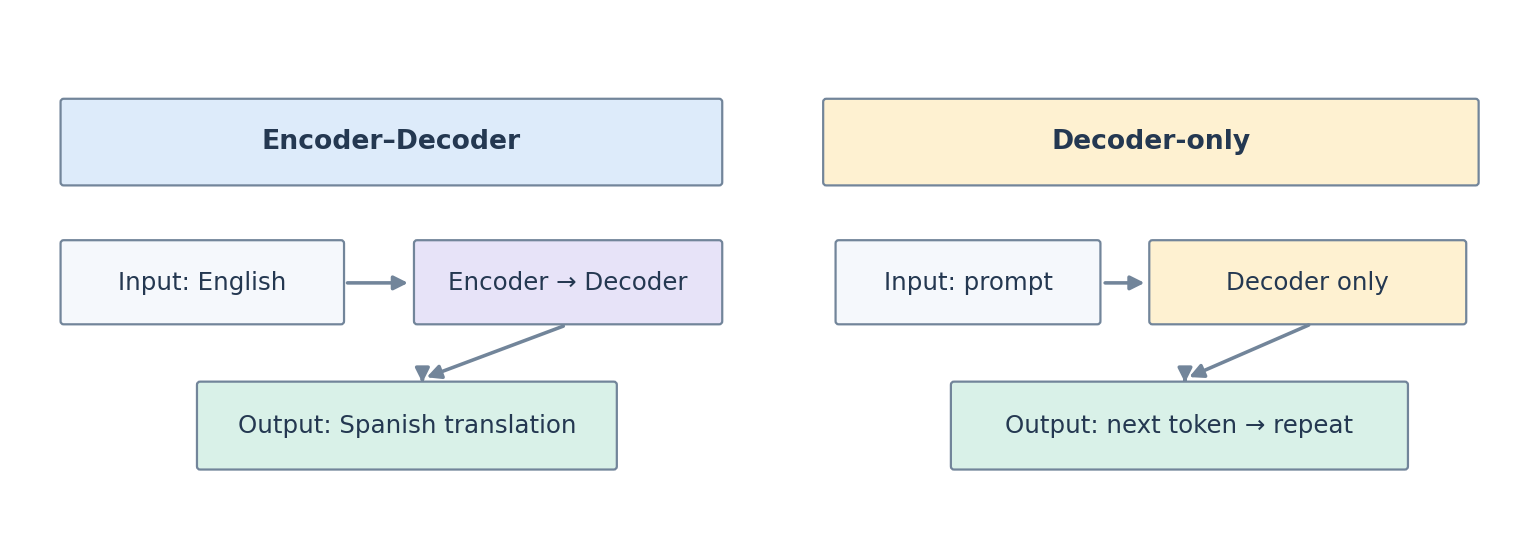

> 주의: Decoder-only의 블록은 원래 Encoder–Decoder의 Decoder를 그대로 복사한 것이 아니다. **Encoder와 연결되는 Cross-Attention은 없고**, 주로 Causal Self-Attention을 사용한다.


## 다음 토큰의 확률분포

예를 들어 모델에 다음과 같이 입력한다.

**`The capital of France is`**

모델은 가능한 다음 **토큰** 각각에 확률을 부여한다.

| 후보 토큰 | 예시 확률 |
|---|---:|
| ` Paris` | 0.65 |
| ` Lyon` | 0.08 |
| ` a` | 0.07 |
| 그 밖의 토큰 | 0.20 |

위 확률은 **설명을 위한 가상 값**이다. 실제 확률은 사전훈련된 작은 모델에서 확인한다.

선택된 다음 토큰을 입력 뒤에 붙여 같은 과정을 반복하면 문장이 길어진다.

```text
The capital of France is
The capital of France is Paris
The capital of France is Paris.
```

이것을 **자기회귀적 생성**(Autoregressive Generation)이라고 한다. 원래 Transformer의 Decoder가 다음 스페인어 토큰을 예측하는 과정과 공통된 원리다.


## Decoder-only의 간단한 활용 두 가지

**활용 ① 텍스트 이어쓰기**

- 입력: `Continue this story: A small dog opened the door...`
- 출력: 주어진 문맥에 이어지는 새로운 문장
- 관찰: 프롬프트가 달라지면 출력도 달라진다.

**활용 ② 간단한 질의응답**

- 입력: `What is the capital of Spain?`
- 출력: 모델이 생성한 답변 텍스트
- 관찰: '답'도 별도의 정답 조회 버튼이 아니라 **다음 토큰 생성을 반복한 결과**다.

둘 다 같은 Decoder-only 생성 원리를 이용한다. 다만 **작은 교육용 모델은 틀리거나 부자연스러운 답변을 생성할 수 있다.**


## 전체 구조를 한 번에 비교

| 구분 | 원래 Transformer Encoder | 원래 Transformer Decoder | Decoder-only 모델 |
|---|---|---|---|
| 주요 역할 | 입력 문장 처리 | 출력 문장 생성 | 프롬프트를 바탕으로 다음 토큰 생성 |
| Self-Attention | 입력 문장 전체 참고 | 이전 출력 토큰만 참고 | 이전 입력·생성 토큰만 참고 |
| Cross-Attention | 없음 | **Encoder 출력 참고** | **없음** |
| 대표 활용 | 번역 모델의 입력 처리 | 번역 모델의 출력 생성 | 이어쓰기, 질의응답 등 |

**정리:** Decoder-only 모델 역시 번역을 수행할 수 있다. 여기서는 **구조의 차이를 명확히 보여주기 위해** Encoder–Decoder는 영어→스페인어 번역으로, Decoder-only는 이어쓰기·질의응답으로 예를 든다.


---
# 학습 내용 확인

1. `token`과 `token ID`는 어떤 차이가 있을까? 임베딩은 왜 필요한가?
2. Q, K, V의 역할을 책 검색에 비유해 설명해 보자.
3. 원래 Transformer의 Encoder 출력은 Decoder의 어느 단계에서 사용되는가?
4. Decoder의 **Masked Self-Attention**과 **Cross-Attention**은 무엇을 다르게 참고하는가?
5. Encoder–Decoder와 Decoder-only의 가장 중요한 구조적 차이는 무엇인가?
6. 작은 언어 모델의 답변이 자연스럽지 않더라도 다음 토큰 생성 원리를 관찰할 수 있는가?
7. **Transformer 구조**와 **사전훈련된 LLM**은 무엇이 다른가?
8. 문장 임베딩 모델은 표현이 다른 질문과 문서를 어떻게 연결하는가?
9. RAG에서는 검색과 답변 생성 중 무엇을 Encoder 계열과 Decoder-only가 각각 담당하는가?

**다음:** `P4_lab_transformer_llm_section1_edited.ipynb`에서 토큰·Attention·번역·생성을 관찰한 뒤, `P4_project_document_search_RAG.ipynb`에서 실제 검색과 근거 기반 답변 생성을 실험한다.

### 참고 자료

- Vaswani et al. (2017), *Attention Is All You Need*
- [Helsinki-NLP 영어→스페인어 번역 모델](https://huggingface.co/Helsinki-NLP/opus-mt-en-es)
- [SmolLM2-135M-Instruct](https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct)
